# Tarea 2 — Inteligencia Artificial



- Integrantes: Andrés Hormazabal, Héctor Vines.
- Profesor: Johan Fuentes. 
- Ayudantes: Dante Libiot, Miguel Pereira, Matias Vasquez.
- URL del dataset utilizado para la pregunta 1: https://www.kaggle.com/datasets/saichaitanyareddyai/spotify-tracks-dataset-audio-features

- URL del dataset utilizado para la pregunta 2: https://www.kaggle.com/datasets/fedesoriano/stellar-classification-dataset-sdss17


In [4]:
import os
import kagglehub
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import learning_curve
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from pandas.plotting import scatter_matrix


In [5]:
# Codigo para descargar los datasets de manera online

path_sdss_dir = kagglehub.dataset_download("fedesoriano/stellar-classification-dataset-sdss17")
sdss_file = os.path.join(path_sdss_dir, "star_classification.csv")
df_sdss = pd.read_csv(sdss_file)
print("Dataset SDSS17 cargado correctamente.")

# 2. Descargar y cargar 
path_spotify= kagglehub.dataset_download("saichaitanyareddyai/spotify-tracks-dataset-audio-features")
spotify_file = os.path.join(path_spotify, "spotify-tracks-dataset-detailed.csv")
df_spotify = pd.read_csv(spotify_file)
print("Dataset Spotify cargado correctamente.")

Dataset SDSS17 cargado correctamente.
Dataset Spotify cargado correctamente.


In [ ]:
#Codigo para importar los datasets desde el proyecto

os.makedirs("data/raw", exist_ok=True)

path_sdss = "data/raw/star_classification.csv"
path_spotify = "data/raw/spotify-tracks-dataset-detailed.csv"


if os.path.exists(path_sdss):
    df_sdss = pd.read_csv(path_sdss)
    print("Dataset SDSS17 cargado correctamente.")
else:
    print(f"Error: Coloca el archivo descargado en la ruta '{path_sdss}'")

if os.path.exists(path_spotify):
    df_spotify = pd.read_csv(path_spotify)
    print("Dataset Spotify cargado correctamente.")
else:
    print("Error")


Dataset SDSS17 cargado correctamente.
Dataset Spotify cargado correctamente.


## Parte 1 — Algoritmos de aprendizaje supervizado

El dataset elegido fue el `spotify-tracks-dataset-detailed.csv` por la cantidad de filas y columnas que tiene, ya que cumple con los requerimientos de la tarea. Además, el área de la música es interesante para nosotros, y poder usar un dataset de este dominio, permitirá ver cómo se ajusta un proceso de Machine Learning para este tipo de datos.


### 1.0 Dataset y variables

| # | Columna | Descripción | Tipo |
|---|---|---|---|
| 0 | track_id | Identificador único de la pista en Spotify | Categórica (texto) |
| 1 | artists | Artista(s) que interpretan la pista, separados por ; | Categórica (texto) |
| 2 | album_name | Nombre del álbum en que aparece la pista | Categórica (texto) |
| 3 | track_name | Nombre de la pista | Categórica (texto) |
| 4 | popularity | Popularidad de la pista (0 a 100), según reproducciones recientes | Numérica discreta |
| 5 | duration_ms | Duración de la pista en milisegundos | Numérica continua |
| 6 | explicit | Indica si la pista tiene contenido explícito | Binaria (booleana) |
| 7 | danceability | Qué tan bailable es la pista (0.0 a 1.0) | Numérica continua |
| 8 | energy | Intensidad y actividad percibida de la pista (0.0 a 1.0) | Numérica continua |
| 9 | key | Tonalidad de la pista (0 = Do, 1 = Do#, ..., 11 = Si) | Categórica (codificada numéricamente) |
| 10 | loudness | Volumen promedio de la pista en decibelios (dB) | Numérica continua |
| 11 | mode | Modalidad de la pista (1 = mayor, 0 = menor) | Binaria |
| 12 | speechiness | Presencia de palabras habladas en la pista (0.0 a 1.0) | Numérica continua |
| 13 | acousticness | Confianza de que la pista sea acústica (0.0 a 1.0) | Numérica continua |
| 14 | instrumentalness | Probabilidad de que la pista no contenga voz (0.0 a 1.0) | Numérica continua |
| 15 | liveness | Probabilidad de que la pista sea una grabación en vivo (0.0 a 1.0) | Numérica continua |
| 16 | valence | Positividad musical transmitida por la pista (0.0 a 1.0) | Numérica continua |
| 17 | tempo | Tempo estimado de la pista en pulsos por minuto (BPM) | Numérica continua |
| 18 | time_signature | Compás estimado de la pista (pulsos por compás) | Numérica discreta |
| 19 | track_genre | Género musical asociado a la pista | Categórica (texto) |

Este es un problema de entrenamiento supervizado, dado que el modelo puede ser entrenado con ejemplos etiquetados.  



> La variable continua $Y_1$ elegida es `popularity`.

> La variable discreta binaria $Y_2$ elegida es `explicit`.



In [22]:

df_spotify.info()
df_spotify.describe()

#Conteno de nulos por columna 
print("\nConteo de nulos por columna:")
print(df_spotify.isnull().sum()[df_spotify.isnull().sum() > 0])

# Limpieza
df_spotify['track_id'].duplicated().sum()
print("Duplicados por track_id:", df_spotify['track_id'].duplicated().sum())
print("Filas completamente duplicadas:", df_spotify.duplicated().sum())

#print(df_spotify.dropna(axis=0, how="any"))

 # Eleccion de variables predictorias
#attributes = [ 'energy','danceability','speechiness','loudness', 'instrumentalness', 'valence' ]
#scatter_matrix(df_spotify[attributes], figsize=(12, 8))
#plt.show() 

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  str    
 1   artists           113999 non-null  str    
 2   album_name        113999 non-null  str    
 3   track_name        113999 non-null  str    
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  int64  
 10  loudness          114000 non-null  float64
 11  mode              114000 non-null  int64  
 12  speechiness       114000 non-null  float64
 13  acousticness      114000 non-null  float64
 14  instrumentalness  114000 non-null  float64
 15  liveness          114000 non-null  float64
 16  valence           114000 non-nu

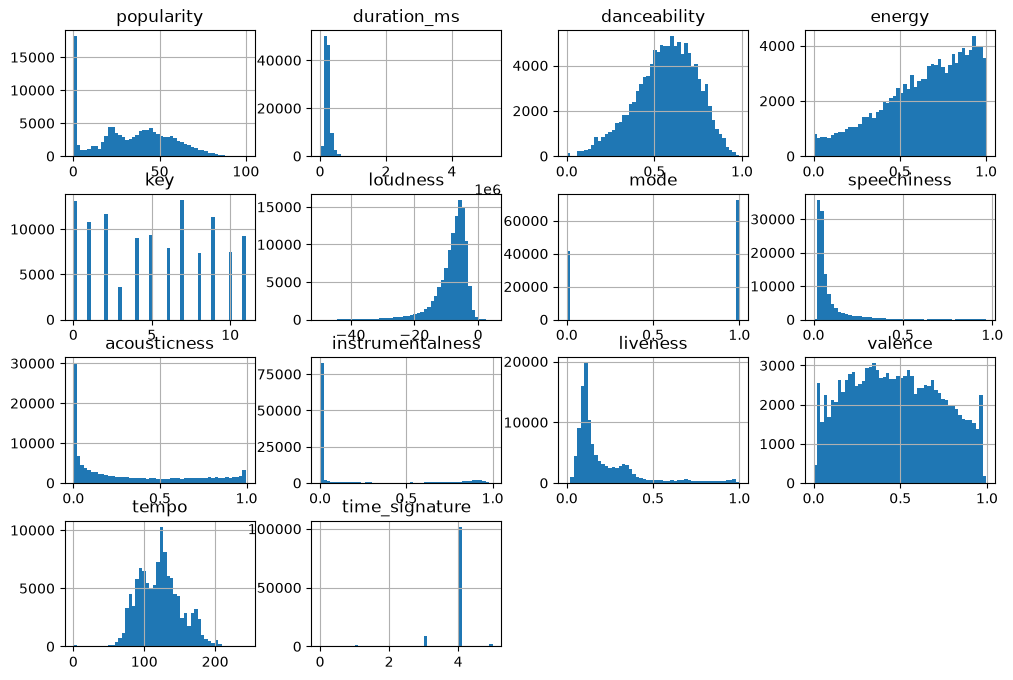

In [7]:

df_spotify.hist(bins=50, figsize=(12,8))
plt.show()

### Variables Predictorias 

Estas variables son  



### 1.1 Selección de variables objetivo (Y1, Y2) y predictoras (X1,...,X10)

_Justificar la elección de Y1 (continua) e Y2 (binaria) y de las 10 variables predictoras iniciales._

In [ ]:
# Definición de Y1, Y2 y X1..X10


### 1.2 Limpieza y preprocesamiento

_Nulos, duplicados, outliers, escalamiento, construcción de Y2 (binarización)._

### 1.3 División del dataset (70% entrenamiento / 15% validación / 15% prueba)

In [ ]:

np.random.seed(42)
def shuffle_and_split_data(data, test_ratio):
    shuffle_indices = np.random.permutation(len(data))
    test_set_size = int(len(data)*test_ratio)
    test_indices = shuffle_indices[:test_set_size]
    train_indices = shuffle_indices[test_set_size:]
    return data.iloc[train_indices], data.iloc[test_indices]

print(f"\n{shuffle_and_split_data(df_spotify, 0.7)}")



(                     track_id                           artists  \
81808  6KtSNVgCmQEvDgIuHoXAkT                   Azaan Sami Khan   
85203  6xpDh0dXrkVp0Po1qrHUd8                         blink-182   
99646  5IjTZ1g8KrIuV97N3OQZ0V                   Gabrielle Aplin   
24692  4FrTPdAy7BbdiJUYw737a6                        Jeff Mills   
11934  1hJrWWK74fKL7eeV3CFOvF                The Rolling Stones   
...                       ...                               ...   
73568  49KVtxjMNy8li0sQt4exTD                           Apparat   
40290  6VRU7PGKvnI9ioGe0o7Rce  Rosa de Saron;Leonardo Gonçalves   
53570  0CaXasBTOik4qmIiAQsEZK        Nathan Dawe;Ella Henderson   
69665  7B7VD5FgF4vQXgZTt0faaI                            Saleem   
93019  0h0dIAeZqoKwYjFNGvnRVV                      Oleg Pogudin   

                                              album_name  \
81808                                          Main Tera   
85203                                 Enema Of The State   
99646        

In [17]:


train_set, test_set = train_test_split(df_spotify, test_size=0.15, train_size=0.7 ,random_state=42)


print(test_set)
#shuffle_and_split_data(df_spotify, 0.15)

                      track_id                     artists  \
113186  6KwkVtXm8OUp2XffN5k7lY            Hillsong Worship   
42819   2dp5I5MJ8bQQHDoFaNRFtX                Internal Rot   
59311   5avw06usmFkFrPjX8NxC40  Zhoobin Askarieh;Ali Sasha   
91368   75hT0hvlESnDJstem0JgyR                 Bryan Adams   
61000   4bY2oZGA5Br3pTE1Jd1IfY                  Nogizaka46   
...                        ...                         ...   
105948  4ehXvrhgK2wuPGB2oC9Ado               Vanilla Beach   
110092  1moFkZDqcjQNeXtyoanLHv            Armin van Buuren   
85224   509LhtMXUxTHkIfjJrrlAC                    Anberlin   
77437   2vTVfHkVRjxahWBUTrXl26              Bonde do Forró   
24694   4spWb4RmxwKl4srXnyRoY9                  Jeff Mills   

                             album_name                        track_name  \
113186                    No Other Name                     No Other Name   
42819                    Grieving Birth                    Failed Organum   
59311              Noise

## Pregunta 1.A — Regresión lineal (Y1 continua)

### 1.A.1 Selección de variables (solo con datos de entrenamiento)

_Justificar el criterio (correlación, información mutua, coeficientes, etc.) y obtener el ranking; definir los subconjuntos de 10, 5 y 3 variables._

### 1.A.2 Entrenamiento de las tres versiones (10, 5 y 3 variables)

### 1.A.3 Comparación en entrenamiento y validación

_Métricas apropiadas: RMSE, MAE, R²._

$\mathrm{RMSE}(\mathbf{X},h)=\sqrt{\frac{1}{m}\sum_{i=1}^{m}\bigl(h(\mathbf{x}^{(i)})-y^{(i)}\bigr)^{2}}$

$\mathrm{MSE}(\mathbf{X},h_{\boldsymbol{\theta}})=\frac{1}{m}\sum_{i=1}^{m}\bigl(\boldsymbol{\theta}^{\!\top}\mathbf{x}^{(i)}-y^{(i)}\bigr)^{2}$

### 1.A.4 Evaluación en prueba de las dos mejores versiones (según validación)

## Pregunta 1.B — Regresión logística (Y2 binaria)

### 1.B.1 Selección de variables (solo con datos de entrenamiento)

### 1.B.2 Entrenamiento de las tres versiones (10, 5 y 3 variables)

### 1.B.3 Comparación en entrenamiento y validación

_Métricas apropiadas: accuracy, precision, recall, F1, ROC-AUC, matriz de confusión._

### 1.B.4 Evaluación en prueba de las dos mejores versiones (según validación)

## 1.C — Análisis final de la Pregunta 1

_Influencia de la cantidad de variables predictoras en el desempeño y la generalización; discusión de overfitting / underfitting (curvas de aprendizaje, brecha train vs. validación)._

---
# Parte 2 — Aprendizaje supervisado vs. semisupervisado

### 2.0 Dataset y variables

_Descripción del dataset SDSS17 (≥15.000 filas, ≥7 características, etiqueta multiclase `class`: GALAXY, STAR, QSO). Justificar variables utilizadas._

In [ ]:
# Carga y exploración inicial de df_sdss

### 2.1 Preprocesamiento

_Selección de características, limpieza, escalamiento, codificación de la etiqueta._

### 2.2 División de datos (80% entrenamiento / 20% testing) y escenarios de etiquetas

_Escenario A: 10% del entrenamiento con etiquetas. Escenario B: 30% del entrenamiento con etiquetas. Fijar semillas._

## 2.A — Baseline supervisado (solo muestras etiquetadas)

### 2.A.1 Regresión Logística — hiperparámetros y justificación (≥3 configuraciones)

_Selección por validación cruzada, sin usar etiquetas desconocidas ni testing. Función de pérdida y métricas._

### 2.A.2 SVM — hiperparámetros y justificación (≥3 configuraciones)

## 2.B — Clustering para pseudoetiquetado

### 2.B.1 K-Means (≥2 configuraciones)

### 2.B.2 DBSCAN (≥2 configuraciones)

### 2.B.3 Estrategia de asignación de pseudoetiquetas

_Criterios de asignación, objetivo de llegar al 60% del conjunto de entrenamiento (reales + estimadas), calidad de las pseudoetiquetas y limitaciones que impidan alcanzar el porcentaje._

## 2.C — Entrenamiento con pseudoetiquetas (semisupervisado)

### 2.C.1 Regresión Logística + pseudoetiquetas (K-Means / DBSCAN)

_≥3 configuraciones de hiperparámetros, selección por validación cruzada._

### 2.C.2 SVM + pseudoetiquetas (K-Means / DBSCAN)

_≥3 configuraciones de hiperparámetros, selección por validación cruzada._

### 2.C.3 Registro de todas las configuraciones evaluadas

_Tabla con configuraciones, funciones de pérdida y métricas._

## 2.D — Comparación final de los seis mejores enfoques

_2 supervisados + 4 semisupervisados, en ambos escenarios (10% y 30%), con al menos 3 semillas aleatorias (media ± desviación estándar)._

## 2.E — Análisis y conclusiones de la Pregunta 2

_Influencia de los hiperparámetros, la cantidad de etiquetas reales y la calidad de las pseudoetiquetas._

---
## Declaración de uso de herramientas generativas

_Declarar específicamente el propósito para el que fueron empleadas (no se permite su uso para diseño de soluciones ni análisis de resultados)._